In [1]:
# ============================================================
# 04.02 MODALITY COMBINATION EVALUATION
# Cell 1: Environment and Imports
# ============================================================

import sys
import json
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn

import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

print("========== 04.02 ENVIRONMENT ==========\n")

print("Python version :", sys.version)
print("PyTorch version:", torch.__version__)
print("NumPy version  :", np.__version__)
print("CUDA available :", torch.cuda.is_available())

device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

print("Device         :", device)

print("\nEnvironment setup: PASSED")

========== 04.02 ENVIRONMENT ==========

Python version : 3.14.4 (tags/v3.14.4:23116f9, Apr  7 2026, 14:10:54) [MSC v.1944 64 bit (AMD64)]
PyTorch version: 2.13.0+cpu
NumPy version  : 2.5.2
CUDA available : False
Device         : cpu

Environment setup: PASSED


In [2]:
# ============================================================
# 04.02 MODALITY COMBINATION EVALUATION
# Cell 2: Project Paths and Validation Data
# ============================================================

# ------------------------------------------------------------
# Locate project root
# ------------------------------------------------------------

current_path = Path.cwd().resolve()

project_root = None

for candidate in [current_path] + list(current_path.parents):

    if (
        (candidate / "06_cross_modal_learning").exists()
        and
        (
            candidate
            / "06_cross_modal_learning"
            / "03_cross_modal_learning"
        ).exists()
    ):
        project_root = candidate
        break

if project_root is None:

    raise FileNotFoundError(
        "Project root could not be located."
    )

# ------------------------------------------------------------
# Phase roots
# ------------------------------------------------------------

phase_root = (
    project_root
    / "06_cross_modal_learning"
)

official_phase3_root = (
    phase_root
    / "03_cross_modal_learning"
)

evaluation_root = (
    phase_root
    / "04_cross_modal_evaluation"
)

reports_dir = (
    evaluation_root
    / "reports"
)

figures_dir = (
    evaluation_root
    / "figures"
)

reports_dir.mkdir(
    parents=True,
    exist_ok=True
)

figures_dir.mkdir(
    parents=True,
    exist_ok=True
)

# ------------------------------------------------------------
# Validation dataset
# ------------------------------------------------------------

pair_dir = (
    phase_root
    / "02_cross_modal_pairing"
    / "pairs"
    / "representation_aware_split"
)

validation_npz_path = (
    pair_dir
    / "02_08_validation_representation_disjoint_pairs.npz"
)

validation_metadata_path = (
    pair_dir
    / "02_08_validation_representation_disjoint_metadata.csv"
)

# ------------------------------------------------------------
# Official baseline checkpoint
# ------------------------------------------------------------

baseline_checkpoint_path = (
    official_phase3_root
    / "03_04_baseline_training"
    / "checkpoints"
    / "03_04_baseline_best_model.pt"
)

# ------------------------------------------------------------
# Verify paths
# ------------------------------------------------------------

assert validation_npz_path.exists()
assert validation_metadata_path.exists()
assert baseline_checkpoint_path.exists()

# ------------------------------------------------------------
# Load validation arrays
# ------------------------------------------------------------

validation_data = np.load(
    validation_npz_path
)

X_val_source = validation_data[
    "source_embeddings"
].astype(np.float32)

X_val_target = validation_data[
    "target_embeddings"
].astype(np.float32)

y_val = validation_data[
    "pair_labels"
].astype(np.float32
)

# ------------------------------------------------------------
# Load metadata
# ------------------------------------------------------------

validation_metadata = pd.read_csv(
    validation_metadata_path
)

print("========== VALIDATION DATA ==========\n")

print(
    "Source embeddings:",
    X_val_source.shape
)

print(
    "Target embeddings:",
    X_val_target.shape
)

print(
    "Labels:",
    y_val.shape
)

print(
    "Metadata:",
    validation_metadata.shape
)

print("\nBaseline checkpoint:")
print(baseline_checkpoint_path)

# ------------------------------------------------------------
# Integrity checks
# ------------------------------------------------------------

assert X_val_source.shape == (448, 32)
assert X_val_target.shape == (448, 32)
assert y_val.shape == (448,)
assert len(validation_metadata) == 448

assert np.isfinite(X_val_source).all()
assert np.isfinite(X_val_target).all()
assert np.isfinite(y_val).all()

print("\nValidation dataset verification: PASSED")
print("Path verification: PASSED")

========== VALIDATION DATA ==========

Source embeddings: (448, 32)
Target embeddings: (448, 32)
Labels: (448,)
Metadata: (448, 8)

Baseline checkpoint:
C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\06_cross_modal_learning\03_cross_modal_learning\03_04_baseline_training\checkpoints\03_04_baseline_best_model.pt

Validation dataset verification: PASSED
Path verification: PASSED


In [3]:
# ============================================================
# 04.02 MODALITY COMBINATION EVALUATION
# Cell 3: Load Official Baseline Model
# ============================================================

class BaselineCrossModalModel(nn.Module):
    """
    Official cross-modal baseline.

    Source: 32-D
    Target: 32-D

    Interaction:
        [S, T, |S-T|, S*T] -> 128-D

    Classifier:
        128 -> 128 -> 64 -> 1
    """

    def __init__(self, embedding_dim=32):

        super().__init__()

        self.classifier = nn.Sequential(

            nn.Linear(
                embedding_dim * 4,
                128
            ),

            nn.ReLU(),

            nn.Linear(
                128,
                64
            ),

            nn.ReLU(),

            nn.Linear(
                64,
                1
            )
        )

    def forward(
        self,
        source,
        target
    ):

        absolute_difference = torch.abs(
            source - target
        )

        elementwise_product = (
            source * target
        )

        combined = torch.cat(
            [
                source,
                target,
                absolute_difference,
                elementwise_product
            ],
            dim=1
        )

        logits = self.classifier(
            combined
        )

        return logits.squeeze(1)


# ------------------------------------------------------------
# Load checkpoint
# ------------------------------------------------------------

baseline_checkpoint = torch.load(
    baseline_checkpoint_path,
    map_location=device,
    weights_only=False
)

# ------------------------------------------------------------
# Create model
# ------------------------------------------------------------

baseline_model = BaselineCrossModalModel(
    embedding_dim=32
).to(device)

# ------------------------------------------------------------
# Load official weights
# ------------------------------------------------------------

baseline_model.load_state_dict(
    baseline_checkpoint[
        "model_state_dict"
    ],
    strict=True
)

# ------------------------------------------------------------
# Freeze and evaluation mode
# ------------------------------------------------------------

baseline_model.eval()

for parameter in baseline_model.parameters():

    parameter.requires_grad = False

# ------------------------------------------------------------
# Parameter verification
# ------------------------------------------------------------

total_parameters = sum(
    p.numel()
    for p in baseline_model.parameters()
)

trainable_parameters = sum(
    p.numel()
    for p in baseline_model.parameters()
    if p.requires_grad
)

assert total_parameters == 24833
assert trainable_parameters == 0

print("========== OFFICIAL BASELINE ==========\n")

print(
    "Total parameters:",
    total_parameters
)

print(
    "Trainable parameters:",
    trainable_parameters
)

print(
    "Checkpoint epoch:",
    baseline_checkpoint["epoch"]
)

print(
    "Saved ROC-AUC:",
    baseline_checkpoint["best_val_roc_auc"]
)

print("\nBaseline loading: PASSED")
print("Baseline frozen: PASSED")

========== OFFICIAL BASELINE ==========

Total parameters: 24833
Trainable parameters: 0
Checkpoint epoch: 13
Saved ROC-AUC: 0.6626674107142857

Baseline loading: PASSED
Baseline frozen: PASSED


In [4]:
# ============================================================
# 04.02 MODALITY COMBINATION EVALUATION
# Cell 4: Generate Validation Predictions
# ============================================================

# ------------------------------------------------------------
# Convert to tensors
# ------------------------------------------------------------

source_tensor = torch.tensor(
    X_val_source,
    dtype=torch.float32,
    device=device
)

target_tensor = torch.tensor(
    X_val_target,
    dtype=torch.float32,
    device=device
)

labels_tensor = torch.tensor(
    y_val,
    dtype=torch.float32,
    device=device
)

# ------------------------------------------------------------
# Inference
# ------------------------------------------------------------

baseline_model.eval()

with torch.no_grad():

    logits_tensor = baseline_model(
        source_tensor,
        target_tensor
    )

    probabilities_tensor = torch.sigmoid(
        logits_tensor
    )

# ------------------------------------------------------------
# NumPy conversion
# ------------------------------------------------------------

baseline_logits = (
    logits_tensor
    .cpu()
    .numpy()
)

baseline_probabilities = (
    probabilities_tensor
    .cpu()
    .numpy()
)

evaluation_labels = (
    labels_tensor
    .cpu()
    .numpy()
)

# ------------------------------------------------------------
# Checks
# ------------------------------------------------------------

assert baseline_logits.shape == (448,)
assert baseline_probabilities.shape == (448,)
assert evaluation_labels.shape == (448,)

assert np.isfinite(
    baseline_logits
).all()

assert np.isfinite(
    baseline_probabilities
).all()

assert np.all(
    baseline_probabilities >= 0
)

assert np.all(
    baseline_probabilities <= 1
)

print("========== VALIDATION INFERENCE ==========\n")

print("Validation pairs:", len(evaluation_labels))

print(
    "Logits shape:",
    baseline_logits.shape
)

print(
    "Probability shape:",
    baseline_probabilities.shape
)

print(
    "Probability mean:",
    float(
        baseline_probabilities.mean()
    )
)

print(
    "Probability std:",
    float(
        baseline_probabilities.std()
    )
)

print("\nInference verification: PASSED")

========== VALIDATION INFERENCE ==========

Validation pairs: 448
Logits shape: (448,)
Probability shape: (448,)
Probability mean: 0.5153837203979492
Probability std: 0.21051548421382904

Inference verification: PASSED


In [5]:
# ============================================================
# 04.02 MODALITY COMBINATION EVALUATION
# Cell 5: Construct Modality Combinations
# ============================================================

# ------------------------------------------------------------
# Copy metadata
# ------------------------------------------------------------

evaluation_metadata = (
    validation_metadata.copy()
)

# ------------------------------------------------------------
# Construct modality combination
# ------------------------------------------------------------

evaluation_metadata[
    "modality_combination"
] = (
    evaluation_metadata[
        "source_modality"
    ].astype(str)
    + "-"
    + evaluation_metadata[
        "target_modality"
    ].astype(str)
)

# ------------------------------------------------------------
# Verify combinations
# ------------------------------------------------------------

expected_combinations = [
    "Genetic-Behavioral",
    "Genetic-Environmental",
    "Behavioral-Environmental"
]

actual_combinations = sorted(
    evaluation_metadata[
        "modality_combination"
    ].unique()
)

print(
    "========== MODALITY COMBINATIONS ==========\n"
)

print("Actual combinations:")

for combination in actual_combinations:

    count = int(
        (
            evaluation_metadata[
                "modality_combination"
            ]
            == combination
        ).sum()
    )

    print(
        f"  {combination}: {count}"
    )

assert set(
    actual_combinations
) == set(
    expected_combinations
)

# ------------------------------------------------------------
# Verify alignment with predictions
# ------------------------------------------------------------

assert len(
    evaluation_metadata
) == len(
    baseline_probabilities
)

print(
    "\nMetadata / prediction alignment: PASSED"
)

print(
    "Modality combination verification: PASSED"
)

========== MODALITY COMBINATIONS ==========

Actual combinations:
  Behavioral-Environmental: 352
  Genetic-Behavioral: 48
  Genetic-Environmental: 48

Metadata / prediction alignment: PASSED
Modality combination verification: PASSED


In [6]:
# ============================================================
# 04.02 MODALITY COMBINATION EVALUATION
# Cell 6: Calculate Per-Modality Metrics
# ============================================================

CLASSIFICATION_THRESHOLD = 0.5

results = []

for combination in expected_combinations:

    # --------------------------------------------------------
    # Select rows belonging to this combination
    # --------------------------------------------------------

    mask = (
        evaluation_metadata[
            "modality_combination"
        ].values
        == combination
    )

    labels = (
        evaluation_labels[mask]
    )

    probabilities = (
        baseline_probabilities[mask]
    )

    # --------------------------------------------------------
    # Predictions
    # --------------------------------------------------------

    predictions = (
        probabilities
        >= CLASSIFICATION_THRESHOLD
    ).astype(int)

    # --------------------------------------------------------
    # Class counts
    # --------------------------------------------------------

    class_0_count = int(
        np.sum(labels == 0)
    )

    class_1_count = int(
        np.sum(labels == 1)
    )

    # --------------------------------------------------------
    # ROC-AUC
    # --------------------------------------------------------

    if len(np.unique(labels)) == 2:

        roc_auc = roc_auc_score(
            labels,
            probabilities
        )

    else:

        roc_auc = np.nan

    # --------------------------------------------------------
    # Classification metrics
    # --------------------------------------------------------

    accuracy = accuracy_score(
        labels,
        predictions
    )

    balanced_accuracy = (
        balanced_accuracy_score(
            labels,
            predictions
        )
    )

    precision = precision_score(
        labels,
        predictions,
        zero_division=0
    )

    recall = recall_score(
        labels,
        predictions,
        zero_division=0
    )

    f1 = f1_score(
        labels,
        predictions,
        zero_division=0
    )

    # --------------------------------------------------------
    # Confusion matrix
    # --------------------------------------------------------

    cm = confusion_matrix(
        labels,
        predictions,
        labels=[0, 1]
    )

    tn, fp, fn, tp = cm.ravel()

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else 0.0
    )

    # --------------------------------------------------------
    # Store result
    # --------------------------------------------------------

    results.append({

        "modality_combination": combination,

        "samples": len(labels),

        "class_0": class_0_count,

        "class_1": class_1_count,

        "roc_auc": roc_auc,

        "accuracy": accuracy,

        "balanced_accuracy":
            balanced_accuracy,

        "precision":
            precision,

        "recall":
            recall,

        "specificity":
            specificity,

        "f1_score":
            f1,

        "true_negative": int(tn),

        "false_positive": int(fp),

        "false_negative": int(fn),

        "true_positive": int(tp)
    })

# ------------------------------------------------------------
# Convert to DataFrame
# ------------------------------------------------------------

modality_results = pd.DataFrame(
    results
)

print(
    "========== MODALITY-WISE RESULTS ==========\n"
)

display(
    modality_results
)

# ------------------------------------------------------------
# Verification
# ------------------------------------------------------------

assert len(
    modality_results
) == 3

assert (
    modality_results["samples"].sum()
    == 448
)

assert (
    modality_results["class_0"].sum()
    == 224
)

assert (
    modality_results["class_1"].sum()
    == 224
)

assert np.isfinite(
    modality_results[
        "roc_auc"
    ]
).all()

print(
    "\nAll three modality combinations evaluated: PASSED"
)

print(
    "Sample count verification: PASSED"
)

print(
    "Class count verification: PASSED"
)

print(
    "Metric finite check: PASSED"
)

========== MODALITY-WISE RESULTS ==========



,modality_combination,samples,class_0,class_1,roc_auc,accuracy,balanced_accuracy,precision,recall,specificity,f1_score,true_negative,false_positive,false_negative,true_positive
0,Genetic-Behavioral,48,24,24,0.807292,0.729167,0.729167,0.720000,0.750000,0.708333,0.734694,17,7,6,18
1,Genetic-Environmental,48,24,24,0.501736,0.500000,0.500000,0.500000,0.541667,0.458333,0.520000,11,13,11,13
2,Behavioral-Environmental,352,176,176,0.659607,0.610795,0.610795,0.606557,0.630682,0.590909,0.618384,104,72,65,111



All three modality combinations evaluated: PASSED
Sample count verification: PASSED
Class count verification: PASSED
Metric finite check: PASSED


In [7]:
# ============================================================
# 04.02 MODALITY COMBINATION EVALUATION
# Cell 7: Save Evaluation Results
# ============================================================

# ------------------------------------------------------------
# CSV
# ------------------------------------------------------------

modality_metrics_csv_path = (
    reports_dir
    / "04_02_modality_combination_metrics.csv"
)

modality_results.to_csv(
    modality_metrics_csv_path,
    index=False
)

# ------------------------------------------------------------
# JSON
# ------------------------------------------------------------

modality_metrics_json_path = (
    reports_dir
    / "04_02_modality_combination_evaluation.json"
)

modality_results_records = (
    modality_results
    .replace({np.nan: None})
    .to_dict(
        orient="records"
    )
)

modality_evaluation_report = {

    "evaluation": {
        "phase": "04",
        "subphase": "04.02",
        "name": (
            "Modality Combination Evaluation"
        ),
        "dataset": (
            "Phase 02.08 representation-aware "
            "validation pairs"
        ),
        "total_validation_pairs": 448,
        "classification_threshold":
            CLASSIFICATION_THRESHOLD
    },

    "modality_combinations":
        modality_results_records,

    "baseline_reference": {
        "checkpoint": str(
            baseline_checkpoint_path
        ),
        "checkpoint_epoch": int(
            baseline_checkpoint["epoch"]
        ),
        "overall_validation_roc_auc":
            float(
                baseline_checkpoint[
                    "best_val_roc_auc"
                ]
            )
    }
}

with open(
    modality_metrics_json_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        modality_evaluation_report,
        f,
        indent=4
    )

# ------------------------------------------------------------
# Verification
# ------------------------------------------------------------

assert modality_metrics_csv_path.exists()
assert modality_metrics_json_path.exists()

loaded_csv = pd.read_csv(
    modality_metrics_csv_path
)

assert len(loaded_csv) == 3

with open(
    modality_metrics_json_path,
    "r",
    encoding="utf-8"
) as f:

    loaded_json = json.load(f)

assert len(
    loaded_json[
        "modality_combinations"
    ]
) == 3

print(
    "========== 04.02 RESULTS SAVED ==========\n"
)

print("CSV:")
print(modality_metrics_csv_path)

print("\nJSON:")
print(modality_metrics_json_path)

print("\nSaved modality combinations:")

for record in modality_metrics_json_report if False else loaded_json["modality_combinations"]:

    print(
        f"  {record['modality_combination']}: "
        f"n={record['samples']}, "
        f"AUC={record['roc_auc']:.6f}"
    )

print("\nCSV verification: PASSED")
print("JSON verification: PASSED")
print("\n04.02 evaluation artifacts: SAVED")

========== 04.02 RESULTS SAVED ==========

CSV:
C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\06_cross_modal_learning\04_cross_modal_evaluation\reports\04_02_modality_combination_metrics.csv

JSON:
C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\06_cross_modal_learning\04_cross_modal_evaluation\reports\04_02_modality_combination_evaluation.json

Saved modality combinations:
  Genetic-Behavioral: n=48, AUC=0.807292
  Genetic-Environmental: n=48, AUC=0.501736
  Behavioral-Environmental: n=352, AUC=0.659607

CSV verification: PASSED
JSON verification: PASSED

04.02 evaluation artifacts: SAVED


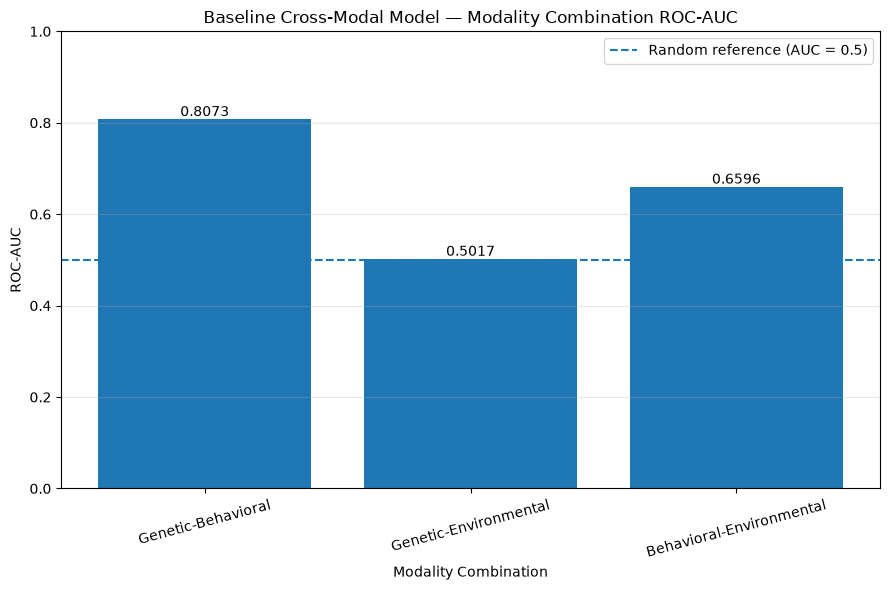

========== MODALITY ROC-AUC FIGURE ==========

Figure saved to:
C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\06_cross_modal_learning\04_cross_modal_evaluation\figures\04_02_modality_combination_roc_auc.png

Figure generation: PASSED


In [8]:
# ============================================================
# 04.02 MODALITY COMBINATION EVALUATION
# Cell 8: Modality ROC-AUC Comparison Figure
# ============================================================

# ------------------------------------------------------------
# Prepare plotting data
# ------------------------------------------------------------

plot_data = modality_results.copy()

# ------------------------------------------------------------
# Create figure
# ------------------------------------------------------------

plt.figure(
    figsize=(9, 6)
)

bars = plt.bar(
    plot_data[
        "modality_combination"
    ],
    plot_data[
        "roc_auc"
    ]
)

# ------------------------------------------------------------
# Add numerical values
# ------------------------------------------------------------

for bar, value in zip(
    bars,
    plot_data["roc_auc"]
):

    plt.text(
        bar.get_x()
        + bar.get_width() / 2,
        bar.get_height(),
        f"{value:.4f}",
        ha="center",
        va="bottom"
    )

# ------------------------------------------------------------
# Reference line at random ROC-AUC
# ------------------------------------------------------------

plt.axhline(
    0.5,
    linestyle="--",
    label="Random reference (AUC = 0.5)"
)

plt.ylabel(
    "ROC-AUC"
)

plt.xlabel(
    "Modality Combination"
)

plt.title(
    "Baseline Cross-Modal Model — "
    "Modality Combination ROC-AUC"
)

plt.ylim(
    0,
    1
)

plt.xticks(
    rotation=15
)

plt.legend()

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

modality_auc_figure_path = (
    figures_dir
    / "04_02_modality_combination_roc_auc.png"
)

plt.savefig(
    modality_auc_figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# Verification
# ------------------------------------------------------------

assert modality_auc_figure_path.exists()

print(
    "========== MODALITY ROC-AUC FIGURE ==========\n"
)

print(
    "Figure saved to:"
)

print(
    modality_auc_figure_path
)

print(
    "\nFigure generation: PASSED"
)

In [9]:
# ============================================================
# 04.02 MODALITY COMBINATION EVALUATION
# Cell 9: Final Verification
# ============================================================

print(
    "========== 04.02 FINAL VERIFICATION ==========\n"
)

# ------------------------------------------------------------
# Dataset
# ------------------------------------------------------------

assert len(evaluation_labels) == 448

# ------------------------------------------------------------
# Modality combinations
# ------------------------------------------------------------

assert set(
    modality_results[
        "modality_combination"
    ]
) == set(
    expected_combinations
)

# ------------------------------------------------------------
# Counts
# ------------------------------------------------------------

assert (
    modality_results["samples"].sum()
    == 448
)

assert (
    modality_results["class_0"].sum()
    == 224
)

assert (
    modality_results["class_1"].sum()
    == 224
)

# ------------------------------------------------------------
# Metrics
# ------------------------------------------------------------

metric_columns = [
    "roc_auc",
    "accuracy",
    "balanced_accuracy",
    "precision",
    "recall",
    "specificity",
    "f1_score"
]

for column in metric_columns:

    assert np.isfinite(
        modality_results[column]
    ).all()

    assert (
        modality_results[column]
        .between(0, 1)
        .all()
    )

# ------------------------------------------------------------
# Artifacts
# ------------------------------------------------------------

assert modality_metrics_csv_path.exists()
assert modality_metrics_json_path.exists()
assert modality_auc_figure_path.exists()

# ------------------------------------------------------------
# Display summary
# ------------------------------------------------------------

print("Modality combinations evaluated:")
print(
    modality_results[
        [
            "modality_combination",
            "samples",
            "class_0",
            "class_1",
            "roc_auc",
            "accuracy",
            "f1_score"
        ]
    ].to_string(index=False)
)

print("\nDataset verification: PASSED")
print("Modality combination verification: PASSED")
print("Metric verification: PASSED")
print("Artifact verification: PASSED")

print(
    "\n================================================"
)

print(
    "04.02 MODALITY COMBINATION EVALUATION: COMPLETE"
)

print(
    "================================================"
)

========== 04.02 FINAL VERIFICATION ==========

Modality combinations evaluated:
    modality_combination  samples  class_0  class_1  roc_auc  accuracy  f1_score
      Genetic-Behavioral       48       24       24 0.807292  0.729167  0.734694
   Genetic-Environmental       48       24       24 0.501736  0.500000  0.520000
Behavioral-Environmental      352      176      176 0.659607  0.610795  0.618384

Dataset verification: PASSED
Modality combination verification: PASSED
Metric verification: PASSED
Artifact verification: PASSED

04.02 MODALITY COMBINATION EVALUATION: COMPLETE
